> **Bản gốc của nhóm, giữ để đối chiếu — không dùng 86,61% làm kết quả chính.**
> Hạn chế: (1) chọn epoch theo `val_accuracy` trên **tập test** (`validation_data=(X_test, y_test)`); (2) không mask padding
> (đệm cứng 256 token, ~90% là padding); (3) lr 1e-5; (4) không có ablation. Bản làm lại đúng quy trình: notebook 04 và 05.

In [11]:
import xml.etree.ElementTree as ET
import pandas as pd
import xml.etree.ElementTree as ET
import pandas as pd

def parse_xml(file_path):
    tree = ET.parse(file_path)
    root = tree.getroot()

    data = []

    for review in root.findall('Review'):
        sentences = review.find('sentences')
        if sentences is None:
            continue

        for sentence in sentences.findall('sentence'):
            text_elem = sentence.find('text')
            if text_elem is None:
                continue

            text = text_elem.text.strip()

            opinions = sentence.find('Opinions')

            # bỏ câu không có label
            if opinions is None:
                continue

            for opinion in opinions.findall('Opinion'):
                category = opinion.get('category')
                polarity = opinion.get('polarity')

                data.append({
                    "sentence": text,
                    "category": category,
                    "polarity": polarity
                })

    return pd.DataFrame(data)
import os
KAGGLE_DIR = "/kaggle/input/datasets/fouadaurag20/semeval-2016-absa-task5"
DATA_DIR = KAGGLE_DIR if os.path.exists(KAGGLE_DIR) else "./data"   # chạy local: đặt file XML vào Final-Project/data/
train_path = f"{DATA_DIR}/restaurants_train_sb1.xml"
test_path  = f"{DATA_DIR}/restaurants_test_sb1.xml"

train_df = parse_xml(train_path)
test_df  = parse_xml(test_path)

print("Train size:", len(train_df))
print("Test size :", len(test_df))
df = pd.concat([train_df, test_df], ignore_index=True)

print(df.head())
print("Total samples:", len(df))

Train size: 2507
Test size : 859
                                            sentence            category  \
0  Judging from previous posts this used to be a ...  RESTAURANT#GENERAL   
1  We, there were four of us, arrived at noon - t...     SERVICE#GENERAL   
2  They never brought us complimentary noodles, i...     SERVICE#GENERAL   
3  The food was lousy - too sweet or too salty an...        FOOD#QUALITY   
4  The food was lousy - too sweet or too salty an...  FOOD#STYLE_OPTIONS   

   polarity  
0  negative  
1  negative  
2  negative  
3  negative  
4  negative  
Total samples: 3366


In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
print(train_df['category'].value_counts())
print(train_df['polarity'].value_counts())

category
FOOD#QUALITY                849
SERVICE#GENERAL             449
RESTAURANT#GENERAL          422
AMBIENCE#GENERAL            255
FOOD#STYLE_OPTIONS          137
RESTAURANT#MISCELLANEOUS     98
FOOD#PRICES                  90
RESTAURANT#PRICES            80
DRINKS#QUALITY               47
DRINKS#STYLE_OPTIONS         32
LOCATION#GENERAL             28
DRINKS#PRICES                20
Name: count, dtype: int64
polarity
positive    1657
negative     749
neutral      101
Name: count, dtype: int64


In [14]:
print(test_df['category'].value_counts())
print(test_df['polarity'].value_counts())

category
FOOD#QUALITY                313
SERVICE#GENERAL             155
RESTAURANT#GENERAL          142
AMBIENCE#GENERAL             66
FOOD#STYLE_OPTIONS           55
RESTAURANT#MISCELLANEOUS     33
FOOD#PRICES                  23
DRINKS#QUALITY               22
RESTAURANT#PRICES            21
LOCATION#GENERAL             13
DRINKS#STYLE_OPTIONS         12
DRINKS#PRICES                 4
Name: count, dtype: int64
polarity
positive    611
negative    204
neutral      44
Name: count, dtype: int64


In [15]:
!pip install imbalanced-learn

In [16]:
!pip install emoji

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 10.3 MB/s eta 0:00:00


In [17]:
import numpy as np
import torch
import re
import emoji
from transformers import AutoTokenizer, AutoModel
from sklearn.preprocessing import LabelEncoder

# =========================
# CONFIG
# =========================
MAX_LEN = 256
BATCH_SIZE = 16
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =========================
# PREPROCESSING
# =========================
def preprocess(text):
    if not isinstance(text, str):
        return ""

    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = emoji.demojize(text)
    text = " ".join(text.split())
    return text


def convert_aspect(cat):
    if not isinstance(cat, str):
        return ""
    return cat.replace('#', ' ').replace('_', ' ')


# =========================
# TOKENIZER
# =========================
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def encode_texts(aspects, sentences):

    # ✅ APPLY PREPROCESSING HERE
    aspects = [preprocess(convert_aspect(a)) for a in aspects]
    sentences = [preprocess(s) for s in sentences]

    enc = tokenizer(
        aspects,
        sentences,
        padding='max_length',
        truncation=True,
        max_length=MAX_LEN,
        return_tensors='pt'
    )

    token_type_ids = enc['token_type_ids']

    return enc['input_ids'], enc['attention_mask'], token_type_ids


# =========================
# BERT MODEL
# =========================
bert_model = AutoModel.from_pretrained("bert-base-uncased")
bert_model.to(device)
bert_model.eval()

def get_embeddings_batch(input_ids, attention_mask, token_type_ids):
    all_outputs = []

    for i in range(0, input_ids.size(0), BATCH_SIZE):
        ids = input_ids[i:i+BATCH_SIZE].to(device)
        mask = attention_mask[i:i+BATCH_SIZE].to(device)
        tt   = token_type_ids[i:i+BATCH_SIZE].to(device)

        with torch.no_grad():
            outputs = bert_model(
                input_ids=ids,
                attention_mask=mask,
                token_type_ids=tt
            )

        all_outputs.append(outputs.last_hidden_state.cpu())

    return torch.cat(all_outputs, dim=0).numpy()


# =========================
# ENCODE DATA
# =========================
print("Encoding BERT features...")

input_ids_train, attn_train, tt_train = encode_texts(
    train_df['category'].tolist(),
    train_df['sentence'].tolist()
)

X_train = get_embeddings_batch(input_ids_train, attn_train, tt_train)

input_ids_test, attn_test, tt_test = encode_texts(
    test_df['category'].tolist(),
    test_df['sentence'].tolist()
)

X_test = get_embeddings_batch(input_ids_test, attn_test, tt_test)


# =========================
# LABEL
# =========================
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(train_df['polarity'])
y_test  = label_encoder.transform(test_df['polarity'])


# =========================
# CHECK
# =========================
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoding BERT features...
X_train: (2507, 256, 768)
X_test : (859, 256, 768)
y_train: (2507,)
y_test : (859,)


In [18]:
'''
from imblearn.over_sampling import RandomOverSampler

# =========================
# RESHAPE (quan trọng)
# =========================
# X_train đang là (N, seq_len, hidden_size)
# RandomOverSampler cần (N, features) → ta flatten

N, T, H = X_train.shape
X_train_flat = X_train.reshape(N, T * H)

# =========================
# OVERSAMPLING
# =========================
ros = RandomOverSampler(random_state=42)

X_resampled, y_resampled = ros.fit_resample(X_train_flat, y_train)

# =========================
# RESHAPE BACK
# =========================
X_train_balanced = X_resampled.reshape(-1, T, H)
y_train_balanced = y_resampled

# =========================
# CHECK
# =========================
print("Before:", X_train.shape, y_train.shape)
print("After :", X_train_balanced.shape, y_train_balanced.shape)
'''

'\nfrom imblearn.over_sampling import RandomOverSampler\n\n# =========================\n# RESHAPE (quan trọng)\n# =========================\n# X_train đang là (N, seq_len, hidden_size)\n# RandomOverSampler cần (N, features) → ta flatten\n\nN, T, H = X_train.shape\nX_train_flat = X_train.reshape(N, T * H)\n\n# =========================\n# OVERSAMPLING\n# =========================\nros = RandomOverSampler(random_state=42)\n\nX_resampled, y_resampled = ros.fit_resample(X_train_flat, y_train)\n\n# =========================\n# RESHAPE BACK\n# =========================\nX_train_balanced = X_resampled.reshape(-1, T, H)\ny_train_balanced = y_resampled\n\n# =========================\n# CHECK\n# =========================\nprint("Before:", X_train.shape, y_train.shape)\nprint("After :", X_train_balanced.shape, y_train_balanced.shape)\n'

In [19]:
import tensorflow as tf
import numpy as np

tf.keras.backend.clear_session()

num_classes = len(np.unique(y_train))

# =========================
# Mean Pooling
# =========================
@tf.keras.utils.register_keras_serializable()
class MeanPooling(tf.keras.layers.Layer):
    def call(self, x):
        return tf.reduce_mean(x, axis=1)

# =========================
# INPUT
# =========================
inputs = tf.keras.Input(shape=(256, 768))
V = inputs

# =========================
# 🔹 GRU
# =========================
out1 = tf.keras.layers.GRU(
    128,
    return_sequences=True
)(V)

# =========================
# 🔹 BiLSTM
# =========================
out_fw, out_bw = tf.keras.layers.Bidirectional(
    tf.keras.layers.LSTM(128, return_sequences=True),
    merge_mode=None
)(out1)

# =========================
# 🔹 Multi-head Attention (GIỮ NGUYÊN NHƯNG FIX)
# =========================
def self_att(x):
    attn = tf.keras.layers.MultiHeadAttention(
        num_heads=4,
        key_dim=64
    )(x, x)

    # 🔥 THÊM residual + norm (QUAN TRỌNG)
    x = tf.keras.layers.Add()([x, attn])
    x = tf.keras.layers.LayerNormalization()(x)

    return x

A1 = self_att(V)
A2 = self_att(out1)
A3 = self_att(out_fw)
A4 = self_att(out_bw)

# =========================
# 🔹 FUSION (THÊM STABILIZE)
# =========================
x = tf.keras.layers.Concatenate(axis=-1)([A1, A2, A3, A4])

# 🔥 thêm layer này để tránh nổ feature
x = tf.keras.layers.Dense(256, activation='relu')(x)
x = tf.keras.layers.LayerNormalization()(x)

# =========================
# 🔹 CONV
# =========================
x = tf.keras.layers.Conv1D(
    filters=128,
    kernel_size=3,
    padding='same',
    activation='relu'
)(x)

x = tf.keras.layers.BatchNormalization()(x)

# =========================
# 🔹 POOLING (GIỮ NGUYÊN)
# =========================
x = MeanPooling()(x)

# =========================
# 🔹 CLASSIFIER (GIỮ NGUYÊN + REGULARIZE)
# =========================
x = tf.keras.layers.Dense(512, activation='relu')(x)
x = tf.keras.layers.Dropout(0.3)(x)   # 🔥 tăng nhẹ

x = tf.keras.layers.Dense(256, activation='relu')(x)
x = tf.keras.layers.Dropout(0.2)(x)   # 🔥 tăng nhẹ

outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)

# =========================
# MODEL
# =========================
model = tf.keras.Model(inputs, outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 768)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 256, 128)  │    344,832 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ [(None, 256,      │    263,168 │ gru[0][0]         │
│ (Bidirectional)     │ 128), (None, 256, │            │                   │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 256, 768)  │    787,968 │ input_layer[0][0… │
│ (MultiHeadAttentio… │                   │            │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 256, 128)  │    131,968 │ gru[0][0],        │
│ (MultiHeadAttentio… │                   │            │ gru[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 256, 128)  │    131,968 │ bidirectional[0]… │
│ (MultiHeadAttentio… │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 256, 128)  │    131,968 │ bidirectional[0]… │
│ (MultiHeadAttentio… │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 256, 768)  │          0 │ input_layer[0][0… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 256, 128)  │          0 │ gru[0][0],        │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 256, 128)  │          0 │ bidirectional[0]… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 256, 128)  │          0 │ bidirectional[0]… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 256, 768)  │      1,536 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 256, 128)  │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 256, 128)  │        256 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 256, 128)  │        256 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256, 1152) │          0 │ layer_normalizat… │
│ (Concatenate)       │                   │            │ layer_normalizat… │
│                     │                   │            │ layer_normalizat… │
│                     │                   │            │ layer_normalizat

 Total params: 2,386,947 (9.11 MB)

 Trainable params: 2,386,691 (9.10 MB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - accuracy: 0.4756 - loss: 1.0050
Epoch 1: val_accuracy improved from None to 0.71944, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
79/79 ━━━━━━━━━━━━━━━━━━━━ 46s 253ms/step - accuracy: 0.5497 - loss: 0.9519 - val_accuracy: 0.7194 - val_loss: 0.9012
Epoch 2/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.7067 - loss: 0.8083
Epoch 2: val_accuracy improved from 0.71944 to 0.76717, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
79/79 ━━━━━━━━━━━━━━━━━━━━ 22s 128ms/step - accuracy: 0.7164 - loss: 0.7687 - val_accuracy: 0.7672 - val_loss: 0.7026
Epoch 3/50
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.7380 - loss: 0.6871
Epoch 3: val_accuracy improved from 0.76717 to 0.78696, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
79/79 ━━━━━━━━━━━━━━━━━━━━ 10s 130ms/step - accuracy: 0.7575 - loss: 0.6669 - val_accu

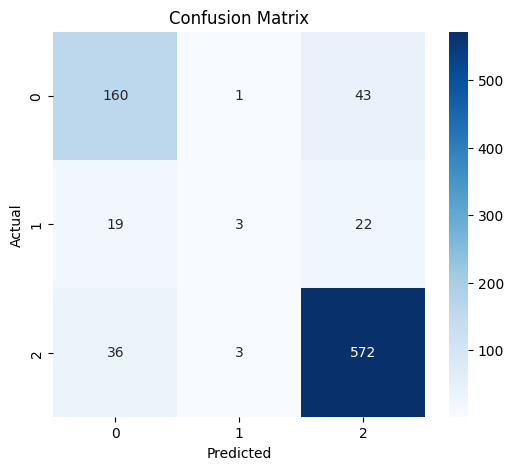

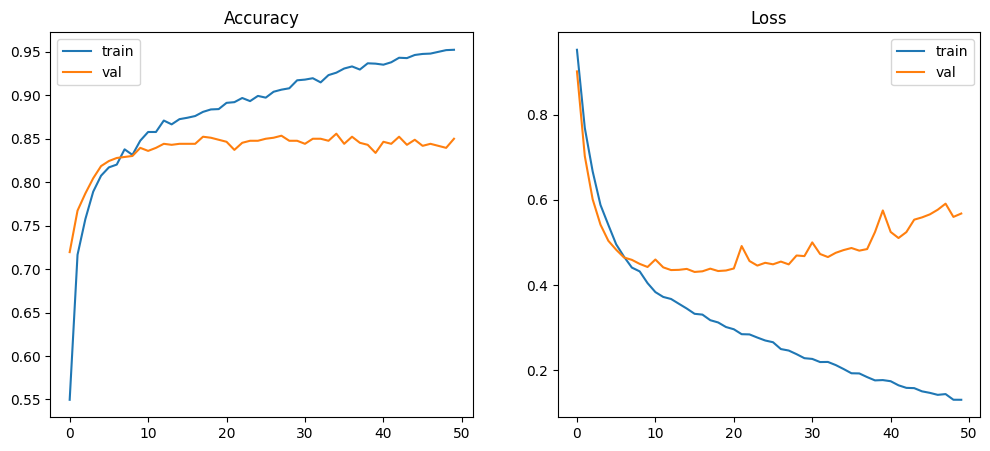

In [20]:

import tensorflow as tf
import numpy as np

# sklearn
from sklearn.metrics import classification_report, confusion_matrix

# visualization
import matplotlib.pyplot as plt
import seaborn as sns
# =========================
# COMPILE
# =========================
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# =========================
# CALLBACKS
# =========================
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_model.keras",
    monitor='val_accuracy',   # 🔥 đổi sang accuracy
    save_best_only=True,
    mode='max',               # 🔥 max vì accuracy càng cao càng tốt
    verbose=1
)

# =========================
# TRAIN (🔥 dùng test làm validation)
# =========================
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=50,
    batch_size=32,
    callbacks=[checkpoint]
)# =========================
# LOAD BEST
# =========================
import keras
keras.config.enable_unsafe_deserialization()
model = tf.keras.models.load_model("best_model.keras")

# =========================
# PREDICT
# =========================
y_pred = model.predict(X_test)
y_pred_labels = np.argmax(y_pred, axis=1)

# =========================
# REPORT
# =========================
print(classification_report(y_test, y_pred_labels, digits=4))
# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(y_test, y_pred_labels)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# =========================
# TRAINING CURVE
# =========================
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title("Loss")
plt.legend()

plt.show()